In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Works from the repository root OR from app/L9 in GitHub Codespaces.
def data_file(filename):
    for folder in [Path.cwd(), *Path.cwd().parents]:
        candidate = folder / "data" / filename
        if candidate.exists():
            return candidate
    raise FileNotFoundError(f"Cannot find data/{filename}. Open this notebook inside ProgrammingForDA.")

## Part A: Classification dataset

The Wisconsin dataset contains **real measured cell features**. We use it only to demonstrate modelling; this notebook must not be used for diagnosis.

In [2]:
cancer = pd.read_csv(data_file("breast_cancer_wisconsin.csv"))
print("Samples/features:", cancer.shape)
print("Labels:\n", cancer["diagnosis"].value_counts())
Xc = cancer.drop(columns="diagnosis")
yc = (cancer["diagnosis"] == "malignant").astype(int)  # 1 = malignant
print("X:", Xc.shape, "y:", yc.shape)

Samples/features: (569, 31)
Labels:
 diagnosis
benign       357
malignant    212
Name: count, dtype: int64
X: (569, 30) y: (569,)


## Split the classification data

Keep the class proportions similar using `stratify=yc`. Use the same split for a fair comparison.

In [3]:
from sklearn.model_selection import train_test_split
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.25, random_state=42, stratify=yc
)

## Compare three classification models

A shallow decision tree is a simple baseline. AdaBoost and gradient boosting combine multiple weak learners in different ways.

Decision stump: test accuracy=0.888
AdaBoost: test accuracy=0.972
Gradient Boosting: test accuracy=0.965


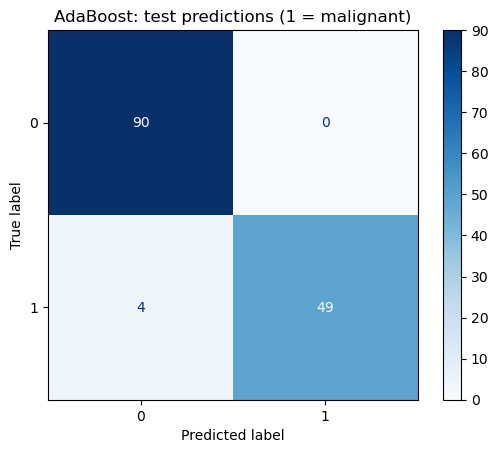

In [4]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
classifiers = {
    "Decision stump": DecisionTreeClassifier(max_depth=1, random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=50, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=50, random_state=42)
}
classification_results = {}
for name, clf in classifiers.items():
    clf.fit(Xc_train, yc_train)
    score = accuracy_score(yc_test, clf.predict(Xc_test))
    classification_results[name] = score
    print(f"{name}: test accuracy={score:.3f}")
ConfusionMatrixDisplay.from_predictions(yc_test, classifiers["AdaBoost"].predict(Xc_test), cmap="Blues")
plt.title("AdaBoost: test predictions (1 = malignant)")
plt.show()

## Part B: Regression dataset

The diabetes dataset has **real patient measurements** and a numerical disease-progression outcome. It is not a classification problem.

In [5]:
diabetes = pd.read_csv(data_file("diabetes_progression.csv"))
print(diabetes.shape)
print(diabetes.head(3))
Xr = diabetes.drop(columns="progression_score")
yr = diabetes["progression_score"]
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    Xr, yr, test_size=0.25, random_state=42
)

(442, 11)
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   

         s4        s5        s6  progression_score  
0 -0.002592  0.019907 -0.017646              151.0  
1 -0.039493 -0.068332 -0.092204               75.0  
2 -0.002592  0.002861 -0.025930              141.0  


## Compare regression models

MAE is average absolute prediction error (lower is better). R² describes explained variation (higher is generally better); it is **not** percentage accuracy.

In [6]:
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import AdaBoostRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score
regressors = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "AdaBoost": AdaBoostRegressor(n_estimators=60, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=60, random_state=42)
}
regression_results = {}
for name, reg in regressors.items():
    reg.fit(Xr_train, yr_train)
    pred = reg.predict(Xr_test)
    mae = mean_absolute_error(yr_test, pred)
    r2 = r2_score(yr_test, pred)
    regression_results[name] = (mae, r2)
    print(f"{name}: MAE={mae:.1f}, R²={r2:.3f}")

Mean baseline: MAE=65.5, R²=-0.014
AdaBoost: MAE=44.5, R²=0.445
Gradient Boosting: MAE=43.8, R²=0.442


## Visualise the comparison

Plot test-set MAE. Lower bars indicate smaller average errors on these held-out observations.

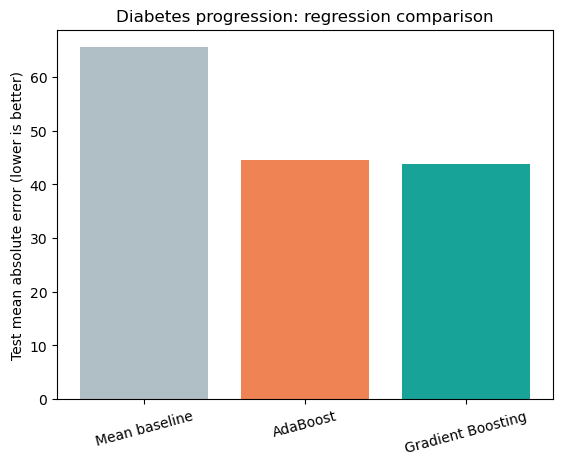

In [7]:
names = list(regression_results)
maes = [regression_results[name][0] for name in names]
plt.bar(names, maes, color=["#b0bec5", "#ef8354", "#17a398"])
plt.ylabel("Test mean absolute error (lower is better)")
plt.title("Diabetes progression: regression comparison")
plt.xticks(rotation=15)
plt.show()

## Your turn — short challenge

Change `n_estimators` for **AdaBoostRegressor** from 60 to 100. Refit it and compare test MAE. Why should final hyperparameter selection use cross-validation rather than repeatedly checking test performance?

Try it yourself first. The instructor copy contains a worked answer.

In [8]:
# TODO: write your answer here.
# Hint: reuse the variables created above.